# Система прогнозирования продаж для «Прилавка»

## Описание задачи

Ваш клиент — компания «Прилавок», новая сеть дарксторов в России, специализирующаяся на быстрой доставке продуктов и товаров повседневного спроса. Компания работает с 2023 года и управляет более чем 45 дарксторами.

**Бизнес-проблема**

Эффективность дарксторов критически зависит от точности управления запасами. Текущая система планирования закупок работает на субъективных оценках аналитиков, что приводит к разным проблемам:
- К дефициту товаров в пиковые периоды (недополучение 3–5% выручки).
- К избыточным запасам и списаниям продуктов с коротким сроком годности (2–3% от выручки).
- К неэффективному использованию времени аналитиков (15–20 часов в неделю на ручное планирование).

**Цель проекта**

Разработать автоматизированную систему прогнозирования недельных продаж для каждого отдела во всех дарксторах с использованием машинного обучения (модель CatBoost). Система будет работать в режиме пакетного внедрения с недельным циклом: модель будет переобучаться каждое воскресенье вечером, а к понедельнику утром прогнозы будут готовы для передачи в систему планирования закупок.

## Описание данных

Для работы доступны исторические данные о продажах за февраль 2023 — октябрь 2025, организованные в виде нескольких таблиц в PostgreSQL:

1. Таблица `sales` — исторические данные о продажах:
   - `Store` — номер даркстора (1–45).
   - `Dept` — номер отдела внутри даркстора (1–99).
   - `Date` — неделя (дата начала недели).
   - `Weekly_Sales` — недельные продажи (руб., целевая переменная).
   - `IsHoliday` — признак праздничной недели.

2. Таблица `stores` — информация о дарксторах:
   - `Store` — номер даркстора.
   - `Type` — тип даркстора (A, B, C).
   - `Size` — размер даркстора в условных единицах.

3. Таблица `features` — внешние факторы:
   - `Store`, `Date` — идентификаторы.
   - `Temperature` — средняя температура за неделю.
   - `Fuel_Price` — средняя цена бензина.
   - `MarkDown1-5` — факторы рекламных акций и скидок.
   - `CPI` — индекс потребительских цен.
   - `Unemployment` — уровень безработицы.

4. Таблица `plan` — данные для инференса (ноябрь 2025 — июль 2026), содержит те же столбцы, что и `sales`, кроме `Weekly_Sales`.

## План работы

Проект состоит из двух частей. В этом ноутбуке вы выполните первую:

1. Первичный анализ и очистка данных.
2. Предобработка и создание признаков.
3. Мониторинг стабильности признаков (PSI).
4. Обучение модели CatBoost и оценка качества.



In [1]:
# Установите зависимости перед запуском notebook:
# pip install -r requirements.txt

In [2]:
# Здесь все необходимые импорты
import io
import pickle
import boto3
import os
from pathlib import Path
from dotenv import load_dotenv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import psycopg2

import warnings
warnings.filterwarnings("ignore")

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from phik import phik_matrix

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

from catboost import CatBoostRegressor

Фиксируем `random_state` для воспроизводимости результатов.

In [3]:
RANDOM_STATE = 42

### Шаг 1. Первичный анализ данных

**Задача:** подключитесь к базе данных PostgreSQL и загрузите данные для анализа.

**Важно:** не храните креды в коде! Используйте переменные окружения или Airflow Variables и Connections.

In [4]:
load_dotenv()

db_settings = {
    'username': os.getenv('POSTGRES_USER'),
    'password': os.getenv('POSTGRES_PASSWORD'),
    'host': os.getenv('POSTGRES_HOST'),
    'port': os.getenv('POSTGRES_PORT', '6432'),
    'database': os.getenv('POSTGRES_DB'),
}

missing_settings = [name for name, value in db_settings.items() if not value]
if missing_settings:
    raise ValueError(f'Не заполнены переменные окружения: {missing_settings}')

connection_url = URL.create(
    drivername='postgresql+psycopg2',
    **db_settings,
)
engine = create_engine(connection_url)

In [5]:
df_sales = pd.read_sql(
    text("""SELECT * FROM sales"""),
    engine
)

df_stores = pd.read_sql(
    text("""SELECT * FROM stores"""),
    engine
)

df_features = pd.read_sql(
    text("""SELECT * FROM features"""),
    engine
)

df_plan= pd.read_sql(
    text("""SELECT * FROM plan"""),
    engine
)


tables = {
    'df_sales': df_sales,
    'df_stores': df_stores,
    'df_features': df_features,
    'df_plan': df_plan
}

for table_name, table in tables.items():
    print(table_name)
    display(table.head(5))

**Задача:** загрузите три таблицы из PostgreSQL: `sales`, `stores`, `features`.

Используйте SQL-запросы для загрузки данных через функцию `pd.read_sql_query()`.

**Задача:** обработайте пропуски и дубликаты в каждой таблице.

Рекомендации по обработке пропусков:
- Для непрерывных переменных — заполнить средним значением.
- Для категориальных переменных — заполнить модой.
- Полные дубликаты строк — удалить.

Перед обработкой изучите структуру пропусков и их причины.

In [6]:
for table_name, table in tables.items():
    print(table_name)
    print()
    print('Общая информация:')
    display(table.info())
    print()
    print('Пропуски:')
    display(table.isna().sum().sort_values(ascending=False))
    print()
    print('Дубликаты:')
    display(table.duplicated().sum())
    print()

df_sales

Общая информация:
<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store         421570 non-null  int64  
 1   dept          421570 non-null  int64  
 2   date          421570 non-null  object 
 3   weekly_sales  421570 non-null  float64
 4   is_holiday    421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB


None


Пропуски:


store           0
dept            0
date            0
weekly_sales    0
is_holiday      0
dtype: int64


Дубликаты:


np.int64(0)

... (15 outputs left out)


Пропуски:


store         0
dept          0
date          0
is_holiday    0
dtype: int64


Дубликаты:


np.int64(0)

**Выводы**

Полных дубликатов нет, пропуски наблюдаются в столбцах 'factor2', 'factor3', 'factor4', 'factor5'. Так как для данных дано пояснение: 'Столбцы MarkDown1 — MarkDown5 содержат большое количество пропусков, так как акции проводятся не каждую неделю.' их следует заполнить нулями, так как пропуск соответствует отсутствию акции. Также столбцы с датами date имеют тип object, нкжно их преобразовать к datetime.

In [7]:
# По условию проекта числовые пропуски заполняем средним значением.
numeric_feature_columns = df_features.select_dtypes(include='number').columns
df_features[numeric_feature_columns] = df_features[numeric_feature_columns].fillna(
    df_features[numeric_feature_columns].mean()
)

df_features.isna().sum().sort_values(ascending=False)

store           0
dept            0
date            0
temperature     0
fuel_price      0
factor1         0
factor2         0
factor3         0
factor4         0
factor5         0
cpi             0
unemployment    0
dtype: int64

In [8]:
df_features['date'] = pd.to_datetime(df_features['date'])
df_sales['date'] = pd.to_datetime(df_sales['date'])
df_plan['date'] = pd.to_datetime(df_plan['date'])

**Задача:** визуализируйте распределение продаж по времени (по месяцам и неделям).

Цель: выявить визуально наличие сезонности в данных. Обратите внимание:
- На периодические всплески (праздники, выходные).
- На общий тренд (рост и спад продаж).
- На аномальные периоды.

In [9]:
# Чтобы посмотреть динамику по месяцам и неделям создадим отдельные колонки с месяцем
df_sales_for_visualization = df_sales.copy()

df_sales_for_visualization['month'] = df_sales_for_visualization['date'].dt.to_period('M')

# В сгруппированных таблицах считаем сумму продаж по всем дарксторам за указанный период
monthly_sales = df_sales_for_visualization.groupby('month')['weekly_sales'].sum() 
weekly_sales = df_sales_for_visualization.groupby('date')['weekly_sales'].sum()
monthly_sales

month
2023-02    1.903330e+08
2023-03    1.819198e+08
2023-04    2.314124e+08
2023-05    1.867109e+08
2023-06    1.922462e+08
2023-07    2.325801e+08
2023-08    1.876401e+08
2023-09    1.772679e+08
2023-10    2.171618e+08
2023-11    2.028534e+08
2023-12    2.887605e+08
2024-01    1.637040e+08
2024-02    1.863313e+08
2024-03    2.228154e+08
2024-04    1.830675e+08
2024-05    1.816482e+08
2024-06    2.373519e+08
2024-07    1.823329e+08
2024-08    1.885993e+08
2024-09    2.208477e+08
2024-10    1.832613e+08
2024-11    2.101624e+08
2024-12    2.880781e+08
2025-01    1.688945e+08
2025-02    1.920636e+08
2025-03    2.315097e+08
2025-04    1.889209e+08
2025-05    1.887665e+08
2025-06    2.406103e+08
2025-07    1.875095e+08
2025-08    2.368508e+08
2025-09    1.806455e+08
2025-10    1.843617e+08
Freq: M, Name: weekly_sales, dtype: float64

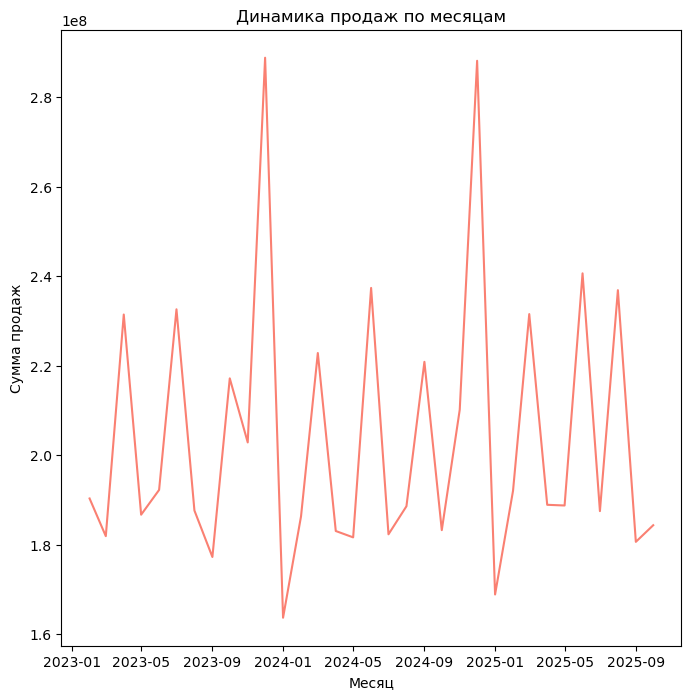

In [10]:
monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(8, 8))
plt.plot(monthly_sales.index, monthly_sales.values, color='salmon')
plt.title('Динамика продаж по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Сумма продаж')
plt.show()

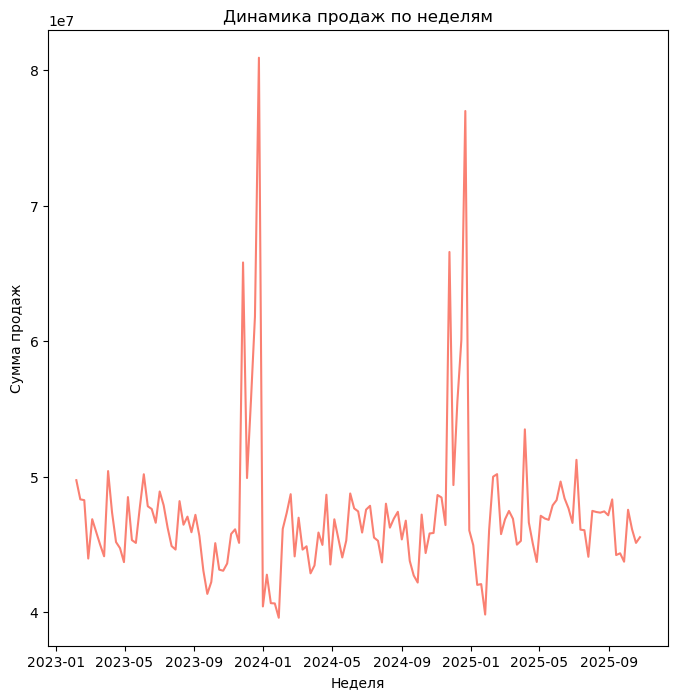

In [11]:
plt.figure(figsize=(8, 8))
plt.plot(weekly_sales.index, weekly_sales.values, color='salmon')
plt.title('Динамика продаж по неделям')
plt.xlabel('Неделя')
plt.ylabel('Сумма продаж')
plt.show()

**Выводы**

По графикам динамики продаж можно сделать вывод, что резкий всплеск продаж наблюдается за месяц до нового года. Кроме того, наблюдается очень мало продаж в конце январе и в сентябре, а также в мае.

**Задача:** объедините три таблицы в одну для дальнейшего анализа.

Используйте операции `merge()` для соединения таблиц по общим ключам.

In [12]:
df_sales.shape

(421570, 5)

In [13]:
df_sales.columns

Index(['store', 'dept', 'date', 'weekly_sales', 'is_holiday'], dtype='str')

In [14]:
df_features.columns

Index(['store', 'dept', 'date', 'temperature', 'fuel_price', 'factor1',
       'factor2', 'factor3', 'factor4', 'factor5', 'cpi', 'unemployment'],
      dtype='str')

In [15]:
df_stores.columns

Index(['store', 'type', 'size'], dtype='str')

In [16]:
# Мерджим таблицы по магазину и дате
df = pd.merge(df_sales, df_features, on=['store', 'date', 'dept'], how='left')
df = pd.merge(df, df_stores, on='store', how='left')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype        
---  ------        --------------   -----        
 0   store         421570 non-null  int64        
 1   dept          421570 non-null  int64        
 2   date          421570 non-null  datetime64[s]
 3   weekly_sales  421570 non-null  float64      
 4   is_holiday    421570 non-null  bool         
 5   temperature   421570 non-null  float64      
 6   fuel_price    421570 non-null  float64      
 7   factor1       421570 non-null  float64      
 8   factor2       421570 non-null  float64      
 9   factor3       421570 non-null  float64      
 10  factor4       421570 non-null  float64      
 11  factor5       421570 non-null  float64      
 12  cpi           421570 non-null  float64      
 13  unemployment  421570 non-null  float64      
 14  type          421570 non-null  str          
 15  size          421570 non-null  int64        


In [17]:
# Проверим на пропуски
df.isna().sum()

store           0
dept            0
date            0
weekly_sales    0
is_holiday      0
temperature     0
fuel_price      0
factor1         0
factor2         0
factor3         0
factor4         0
factor5         0
cpi             0
unemployment    0
type            0
size            0
dtype: int64

**Задача:** оцените корреляцию целевой переменной `Weekly_Sales` с другими признаками.

Используйте метод `.corr()` для расчёта корреляционной матрицы. Ответьте на вопросы:
- Какие признаки сильнее всего коррелируют с продажами?
- Есть ли сильно коррелирующие между собой признаки (мультиколлинеарность)?

In [18]:
# Перед расчётом корреляции явно разделим признаки по типам и уменьшим объём памяти.
float_cols = df.select_dtypes(include=['float']).columns.to_list()
int_cols = df.select_dtypes(include=['integer']).columns.to_list()
cat_cols = df.select_dtypes(include=['object', 'string', 'category']).columns.to_list()
bool_cols = df.select_dtypes(include=['bool']).columns.to_list()

for col in float_cols:
    df[col] = pd.to_numeric(df[col], downcast='float')

for col in int_cols:
    df[col] = pd.to_numeric(df[col], downcast='integer')

print(f'float_cols: {float_cols}')
print(f'int_cols: {int_cols}')
print(f'cat_cols: {cat_cols}')
print(f'bool_cols: {bool_cols}')
df.info()

float_cols: ['weekly_sales', 'temperature', 'fuel_price', 'factor1', 'factor2', 'factor3', 'factor4', 'factor5', 'cpi', 'unemployment']
int_cols: ['store', 'dept', 'size']
cat_cols: ['type']
bool_cols: ['is_holiday']
<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype        
---  ------        --------------   -----        
 0   store         421570 non-null  int8         
 1   dept          421570 non-null  int8         
 2   date          421570 non-null  datetime64[s]
 3   weekly_sales  421570 non-null  float64      
 4   is_holiday    421570 non-null  bool         
 5   temperature   421570 non-null  float32      
 6   fuel_price    421570 non-null  float32      
 7   factor1       421570 non-null  float64      
 8   factor2       421570 non-null  float64      
 9   factor3       421570 non-null  float64      
 10  factor4       421570 non-null  float64      
 11  factor5       421570 non-nul

In [19]:
cat_cols = ['store', 'dept', 'is_holiday', 'type']
target = 'weekly_sales'
num_cols = list(set(float_cols + int_cols) - set(cat_cols) - {target})
print(f'cat_cols: {cat_cols}')
print(f'num_cols: {num_cols}')

cat_cols: ['store', 'dept', 'is_holiday', 'type']
num_cols: ['factor5', 'factor1', 'factor4', 'size', 'cpi', 'fuel_price', 'factor2', 'temperature', 'factor3', 'unemployment']


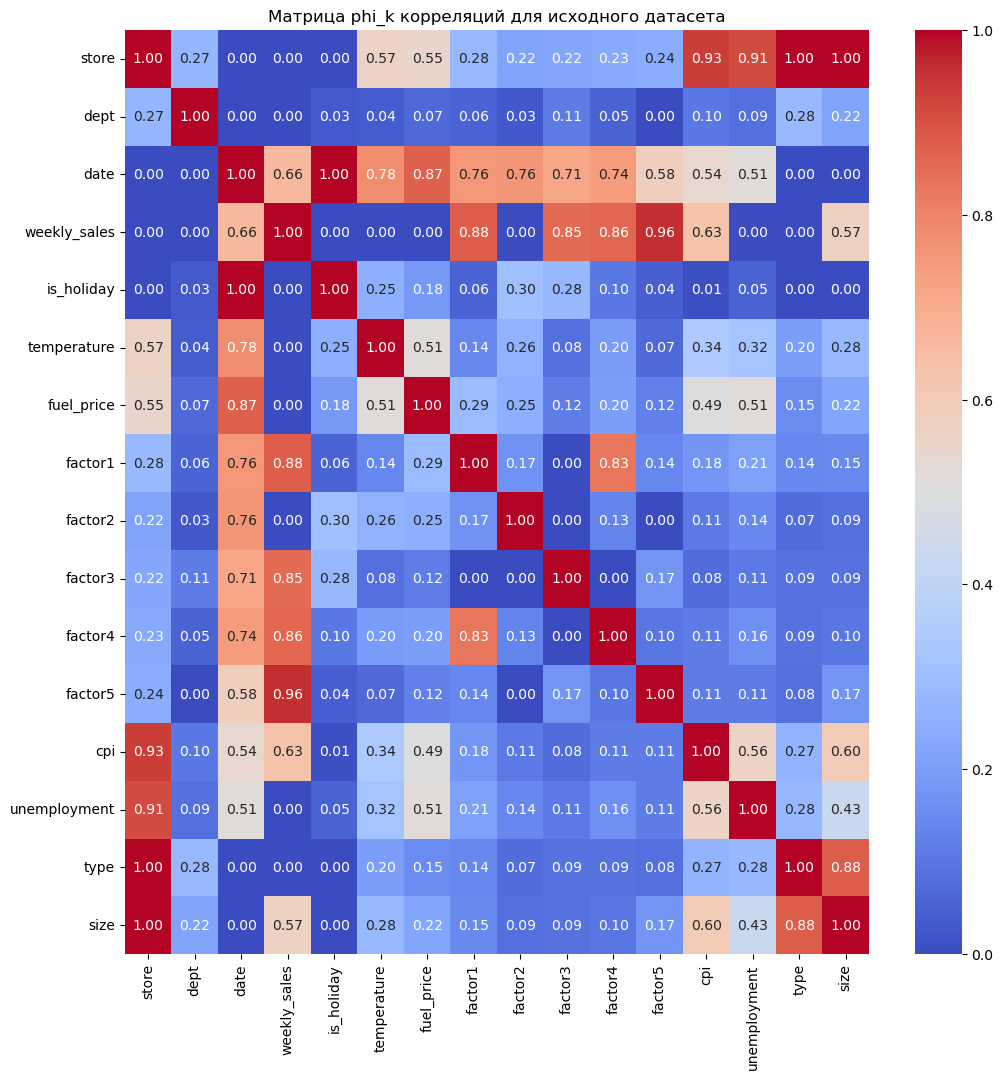

In [20]:
# Посчитаем phi_k корреляцию, чтобы также изучить скоррелированность категориальных прихнаков с целевой переменной
# Возбмем sample, чтобы считалось быстрее
df_sample = df.sample(n=50_000, random_state=RANDOM_STATE)

corr_mat = df_sample.phik_matrix(interval_cols=num_cols)

plt.figure(figsize=(12, 12))
sns.heatmap(corr_mat, cmap='coolwarm', fmt='.2f', annot=True)
plt.title('Матрица phi_k корреляций для исходного датасета')
plt.show()

**Выводы**

 
- Признак `store` сильно скоррелирован с признаками `size` и `type` (`phi_k = 1`), так как номер магазина однозначно определяет его тип и размер. Также высокая связь наблюдается между `type` и `size` (`phi_k ≈ 0.98`), что указывает на частичную избыточность этих признаков.

- Признак `date` показывает высокую корреляцию с `is_holiday` (`phi_k = 1`), поскольку праздничные периоды непосредственно определяются датой. Кроме того, `date` заметно связан с `temperature`, `fuel_price` и признаками `factor1`–`factor5` (`phi_k ≈ 0.59–0.87`). Это объясняется временной природой этих показателей: их значения изменяются в зависимости от периода наблюдения.

- Между макроэкономическими признаками `cpi` и `unemployment` наблюдается умеренная связь (`phi_k ≈ 0.56`). При этом оба признака сильно связаны с `store`, `type` и `size`. Это может быть связано с тем, что разные магазины расположены в различных регионах и для них характерны разные значения макроэкономических показателей.

- Целевой признак `weekly_sales` наиболее сильно связан с `factor5` (`phi_k ≈ 0.96`), `factor1` (`≈ 0.88`), `size` (`≈ 0.86`), `factor4` (`≈ 0.86`) и `factor3` (`≈ 0.85`). Также заметная связь наблюдается с `date` (`≈ 0.66`) и `cpi` (`≈ 0.63`). Эти признаки потенциально могут быть наиболее информативными при построении модели прогнозирования продаж.

- Так как обучаемая модель `Catboost` нормально работает с мультиколлинеарными признаками, поэтому оставим их как есть.

**Задача:** обработайте аномалии в продажах.

Подсказка: могут ли продажи быть отрицательными? Решите, как с ними поступить.

Обоснуйте свой выбор.

In [21]:
df['weekly_sales'].describe()

count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: weekly_sales, dtype: float64

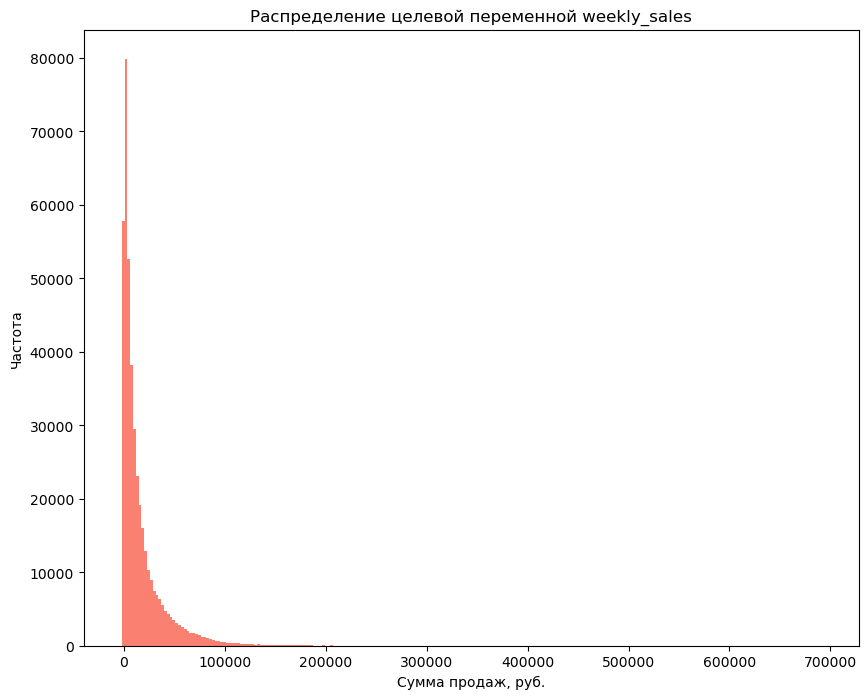

In [22]:
plt.figure(figsize=(10, 8))
plt.hist(df['weekly_sales'], color='salmon', bins=250)
plt.title('Распределение целевой переменной weekly_sales')
plt.xlabel('Сумма продаж, руб.')
plt.ylabel('Частота')
plt.show()

In [23]:
df['weekly_sales'] = df['weekly_sales'].clip(lower=0)
df['weekly_sales'].min()

np.float64(0.0)

**Вывод**

Есть отрицательные продажи, их разумно заменить на 0, так как такие значения предположительно соответствуют факту отсутствия продаж. Распределение `weekly_sales` имеет выраженную правостороннюю асимметрию. Большинство наблюдений сосредоточено в области относительно небольших значений продаж, при этом присутствует длинный правый хвост, сформированный редкими случаями очень высоких продаж.

**Задача:** исследуйте аномально высокие продажи.

Найдите записи с очень высокими продажами (например, топ 0.01% или выше 99.99% квантиля). Попробуйте найти закономерности:
- В какое время года они происходят?
- Связаны ли они с праздниками?
- Какие типы дарксторов и отделы демонстрируют пиковые продажи?

In [24]:
# Фильтруем данные по квантилю 99.9%
quatile_9999 = df['weekly_sales'].quantile(q=0.9999)
df_top_sales = df[df['weekly_sales']>quatile_9999]
df_top_sales.shape

(43, 16)

count        43.000000
mean     375581.769535
std       98975.216501
min      285353.530000
25%      309547.300000
50%      351763.710000
75%      388537.030000
max      693099.360000
Name: weekly_sales, dtype: float64

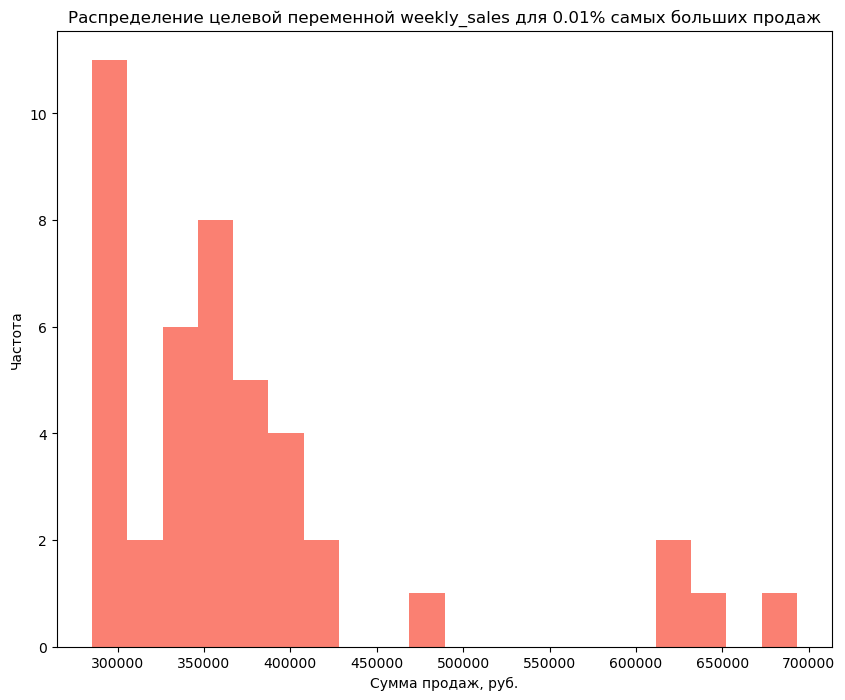

In [25]:
display(df_top_sales['weekly_sales'].describe())

plt.figure(figsize=(10, 8))
plt.hist(df_top_sales['weekly_sales'], color='salmon', bins=20)
plt.title('Распределение целевой переменной weekly_sales для 0.01% самых больших продаж')
plt.xlabel('Сумма продаж, руб.')
plt.ylabel('Частота')
plt.show()

In [26]:
df_top_sales['date']

In [27]:
df_top_sales['is_holiday'].value_counts(normalize=True)

is_holiday
True     0.72093
False    0.27907
Name: proportion, dtype: float64

In [28]:
df_top_sales['dept'].value_counts(normalize=True)

dept
72    0.837209
7     0.139535
92    0.023256
Name: proportion, dtype: float64

In [29]:
df_top_sales['type'].value_counts(normalize=True)

type
A    0.604651
B    0.395349
Name: proportion, dtype: float64

**Вывод**

0.01% самых высоких продаж лежит в диапазоне от 285 до 693 тысяч рублей. Для таких продаж наблюдается выраженная сезонность: большая часть пиков приходится на ноябрь и декабрь, а 72% пиковых значений относятся к праздничным неделям. Чаще всего такие продажи встречаются в отделе 72; заметный вклад также вносит отдел 7. Пиковые значения есть в дарксторах типов A и B.

### Шаг 2. Предобработка признаков и feature engineering

**Задача:** реализуйте функцию `create_temporal_features` для извлечения временных признаков из столбца `Date`.

Извлеките из даты:
- Месяц (`month`).
- Квартал (`quarter`).
- Год (`year`).

Эти признаки помогут модели уловить сезонные паттерны.

In [30]:
def create_temporal_features(df) -> pd.DataFrame:
    df = df.copy()
    df['month'] = df['date'].dt.month
    df['quarter'] = df['date'].dt.quarter
    df['year'] = df['date'].dt.year
    return df

df = create_temporal_features(df)
df.head(10)

In [31]:
assert 'month' in df.columns, 'Месяц не создан!'
assert 'quarter' in df.columns, 'Квартал не создан!'
assert 'year' in df.columns, 'Год не создан!'

**Задача:** cоздайте агрегированные признаки в функции `create_avg_sales_feature` — средние продажи по комбинации «даркстор и отдел».

**Важно: Избегайте утечки данных!**

При создании агрегатов для каждой строки используйте только данные **до** этой даты:
- Для даты 2025-09-08 считайте среднее по данным с начала до 2025-09-07 включительно.
- Для даты 2025-09-15 считайте среднее по данным с начала до 2025-09-14 включительно.

Это критически важно, чтобы модель не использовала информацию из будущего!

In [32]:
def create_avg_sales_feature(df):
    df = df.sort_values(['store', 'dept', 'date']).copy()
    grouped_sales = df.groupby(['store', 'dept'], sort=False)['weekly_sales']
    df['avg_sales_before'] = grouped_sales.transform(
        lambda values: values.shift(1).expanding().mean()
    )
    return df

df = create_avg_sales_feature(df)
df.tail(10)

In [33]:
assert 'avg_sales_before' in df.columns, 'Признак средних продаж не создан!'

**Задача:** создайте лаговые признаки в функции `create_lag_features` — продажи 1, 2 и 4 недели назад.

Лаговые признаки позволяют модели учитывать историю продаж:
- `sales_1week_ago` — продажи неделю назад.
- `sales_2week_ago` — продажи 2 недели назад.
- `sales_4week_ago` — продажи 4 недели назад.

Это одни из самых важных признаков для прогнозирования временных рядов!

In [34]:
def create_lag_features(df):
    df = df.sort_values(['store', 'dept', 'date']).copy()
    grouped_sales = df.groupby(['store', 'dept'], sort=False)['weekly_sales']
    df['sales_1week_ago'] = grouped_sales.shift(1)
    df['sales_2week_ago'] = grouped_sales.shift(2)
    df['sales_4week_ago'] = grouped_sales.shift(4)
    return df

df = create_lag_features(df)
df.tail(10)

In [35]:
assert 'sales_1week_ago' in df.columns, 'Признак sales_1week_ago не создан!'
assert 'sales_2week_ago' in df.columns, 'Признак sales_2week_ago не создан!'
assert 'sales_4week_ago' in df.columns, 'Признак sales_4week_ago не создан!'

**Задача:** cоздайте признаки скользящего среднего продаж за последние 2 и 4 недели в функции `create_rolling_features`.

Скользящее среднее сглаживает колебания и показывает общий тренд:
- `mean_sales_2week` — среднее продаж за последние 2 недели.
- `mean_sales_4week` — среднее продаж за последние 4 недели.

Эти признаки помогают уловить краткосрочные и среднесрочные тренды.

In [36]:
def create_rolling_features(df):
    df = df.sort_values(['store', 'dept', 'date']).copy()
    grouped_sales = df.groupby(['store', 'dept'], sort=False)['weekly_sales']
    df['mean_sales_2week'] = grouped_sales.transform(
        lambda values: values.shift(1).rolling(2).mean()
    )
    df['mean_sales_4week'] = grouped_sales.transform(
        lambda values: values.shift(1).rolling(4).mean()
    )
    return df

df = create_rolling_features(df)

In [37]:
assert 'mean_sales_2week' in df.columns, 'Признак mean_sales_2week не создан!'
assert 'mean_sales_4week' in df.columns, 'Признак mean_sales_4week не создан!'

**Задача:** удалите строки с пропусками.

После создания лаговых и агрегированных признаков неизбежно появятся пропуски (особенно для первых недель, где нет истории). Удалите такие строки с помощью `dropna()`.

In [38]:
df_rows_before = df.shape[0]
df = df.dropna()
print(f'Удалено {df_rows_before-df.shape[0]} строк с пропусками')

Удалено 13134 строк с пропусками


### Шаг 3. Мониторинг стабильности признаков

**Задача:** разделите данные на обучающую и валидационную выборки **по времени**.

Разделение:
- **Обучение**: февраль 2023 — август 2025.
- **Валидация**: сентябрь 2025 — октябрь 2025.

Такое разделение имитирует реальное применение модели: обучаем на прошлых данных, проверяем на будущих.

In [39]:
split_date = pd.Timestamp('2025-09-01')
df_train = df[df['date'] < split_date].copy()
df_val = df[df['date'] >= split_date].copy()

print(f'df_train: {df_train["date"].min()}-{df_train["date"].max()}')
print(f'df_val: {df_val["date"].min()}-{df_val["date"].max()}')

df_train = df_train.drop(columns=['date'])
df_val = df_val.drop(columns=['date'])

df_train: 2023-03-05 00:00:00-2025-08-31 00:00:00
df_val: 2025-09-07 00:00:00-2025-10-26 00:00:00


In [40]:
X_train = df_train.drop(columns=[target])
y_train = df_train[target]
X_val = df_val.drop(columns=[target])
y_val = df_val[target]

print(f'X_train: {X_train.shape}')
print(f'y_train: {y_train.shape}')
print(f'X_val: {X_val.shape}')
print(f'y_val: {y_val.shape}')

X_train: (384726, 23)
y_train: (384726,)
X_val: (23710, 23)
y_val: (23710,)


Выборка разделена в соответствии со временем

**Задача:** рассчитайте PSI для всех признаков.

PSI измеряет стабильность распределения признака между обучающей и валидационной выборками:
- **PSI < 0.1** — признак стабилен, можно использовать.
- **0.1 ≤ PSI < 0.2** — умеренный дрейф, требуется внимание.
- **PSI ≥ 0.2** — значительный дрейф, признак нестабилен.

In [41]:
def psi_categorical(expected, actual, epsilon=1e-6):
    """PSI для категориальных признаков."""

    expected = expected.astype('object').fillna('__MISSING__')
    actual = actual.astype('object').fillna('__MISSING__')

    categories = expected.unique().tolist()

    # Добавляем категории, которые появились только в validation
    for category in actual.unique():
        if category not in categories:
            categories.append(category)

    expected_dist = (
        expected.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    actual_dist = (
        actual.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    expected_dist = np.where(expected_dist == 0, epsilon, expected_dist)
    actual_dist = np.where(actual_dist == 0, epsilon, actual_dist)

    return np.sum(
        (actual_dist - expected_dist)
        * np.log(actual_dist / expected_dist)
    )


def psi_numeric(expected, actual, bins=10, epsilon=1e-6):
    """PSI для числовых признаков. Бины строятся только по train."""

    expected = pd.to_numeric(expected, errors='coerce')
    actual = pd.to_numeric(actual, errors='coerce')

    train_notna = expected.dropna()

    # Если признак практически константный
    if train_notna.nunique() <= 1:
        return psi_categorical(expected, actual, epsilon)

    # Квантильные границы строим ТОЛЬКО по train
    edges = (
    train_notna
    .quantile(np.linspace(0, 1, bins + 1))
    .drop_duplicates()
    .to_numpy(copy=True)
    )

    # Защита от слишком малого количества уникальных границ
    if len(edges) < 2:
        return psi_categorical(expected, actual, epsilon)

    # Чтобы значения validation за пределами train тоже попали в бины
    edges[0] = -np.inf
    edges[-1] = np.inf

    expected_bins = pd.cut(
        expected,
        bins=edges,
        include_lowest=True
    ).astype('object').fillna('__MISSING__')

    actual_bins = pd.cut(
        actual,
        bins=edges,
        include_lowest=True
    ).astype('object').fillna('__MISSING__')

    categories = expected_bins.unique().tolist()

    for category in actual_bins.unique():
        if category not in categories:
            categories.append(category)

    expected_dist = (
        expected_bins.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    actual_dist = (
        actual_bins.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    expected_dist = np.where(expected_dist == 0, epsilon, expected_dist)
    actual_dist = np.where(actual_dist == 0, epsilon, actual_dist)

    return np.sum(
        (actual_dist - expected_dist)
        * np.log(actual_dist / expected_dist)
    )

def calculate_psi_all(X_train, X_val, bins=10):

    categorical_cols = [
        'store',
        'dept',
        'is_holiday',
        'type',
        'month',
        'quarter',
        'year'
    ]

    results = []

    for col in X_train.columns:

        if col in categorical_cols:
            psi = psi_categorical(
                X_train[col],
                X_val[col]
            )

        else:
            psi = psi_numeric(
                X_train[col],
                X_val[col],
                bins=bins
            )

        if psi < 0.1:
            status = 'Стабилен'
        elif psi < 0.2:
            status = 'Умеренный дрейф'
        else:
            status = 'Значительный дрейф'

        results.append({
            'feature': col,
            'psi': psi,
            'status': status
        })

    return (
        pd.DataFrame(results)
        .sort_values('psi', ascending=False)
        .reset_index(drop=True)
    )

In [42]:
psi_results = calculate_psi_all(
    X_train,
    X_val,
    bins=10
)

psi_results

,feature,psi,status
0,month,11.535689,Значительный дрейф
1,year,10.321684,Значительный дрейф
2,quarter,6.981872,Значительный дрейф
3,fuel_price,6.607474,Значительный дрейф
4,cpi,4.239600,Значительный дрейф
5,factor5,2.491246,Значительный дрейф
6,factor1,1.906281,Значительный дрейф
7,factor4,1.650467,Значительный дрейф
8,factor3,1.636703,Значительный дрейф
9,temperature,1.400951,Значительный дрейф


In [43]:
features_with_high_psi = psi_results[psi_results['status']=='Значительный дрейф']['feature'].to_list()
features_with_high_psi

['month',
 'year',
 'quarter',
 'fuel_price',
 'cpi',
 'factor5',
 'factor1',
 'factor4',
 'factor3',
 'temperature',
 'factor2',
 'unemployment']

**Задача:** интерпретируйте результаты PSI.

Проанализируйте полученные значения PSI:
- Какие признаки стабильны?
- Для каких признаков наблюдается дрейф?

Визуализируйте распределения признаков с высоким PSI на обучении и валидации для лучшего понимания.

**Вывод**

Значительный дрейф (`PSI ≥ 0.2`) наблюдается для признаков
`month`, `year`, `quarter`, `fuel_price`, `cpi`, `factor3`,
`factor1`, `factor5`, `factor2`, `temperature`, `factor4`,
`unemployment`.

Высокий PSI у части признаков является ожидаемым следствием временного
разбиения данных. Например, `year` напрямую связан с течением времени,
а распределения `month` и `quarter` могут различаться между обучающим
и валидационным периодами из-за сезонности.

Также изменение распределений `temperature`, `fuel_price`, `cpi`
и `unemployment` не обязательно является признаком плохого качества
данных. Эти показатели естественным образом изменяются во времени и
могут содержать полезную информацию о сезонности и экономической
ситуации.

Следовательно, высокий PSI следует рассматривать как сигнал о наличии
distribution shift, а не как безусловное основание для удаления признака.
Механическое исключение всех признаков с `PSI ≥ 0.2` может привести к
потере значительной части полезной информации. Поэтому мы раздели выборки на 2 части: с удаленными признаками и без удаленных признаков и посмотрим как это повлияет на качество модели на val.

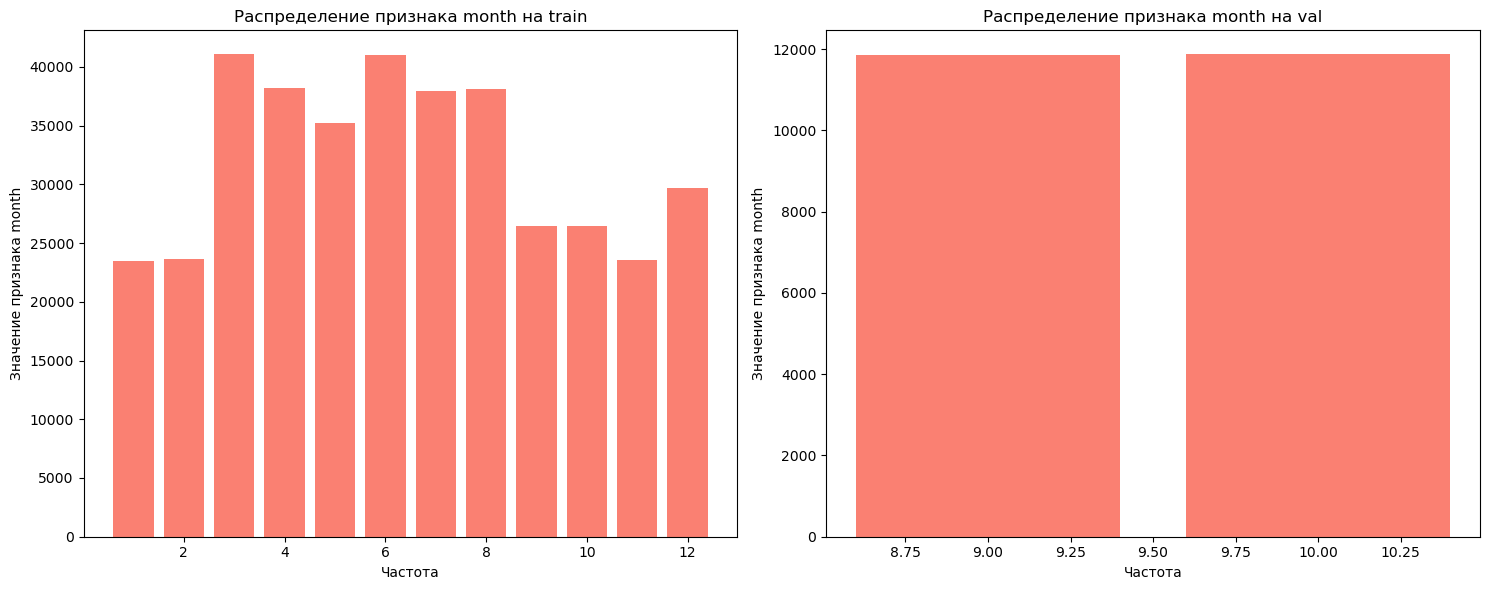

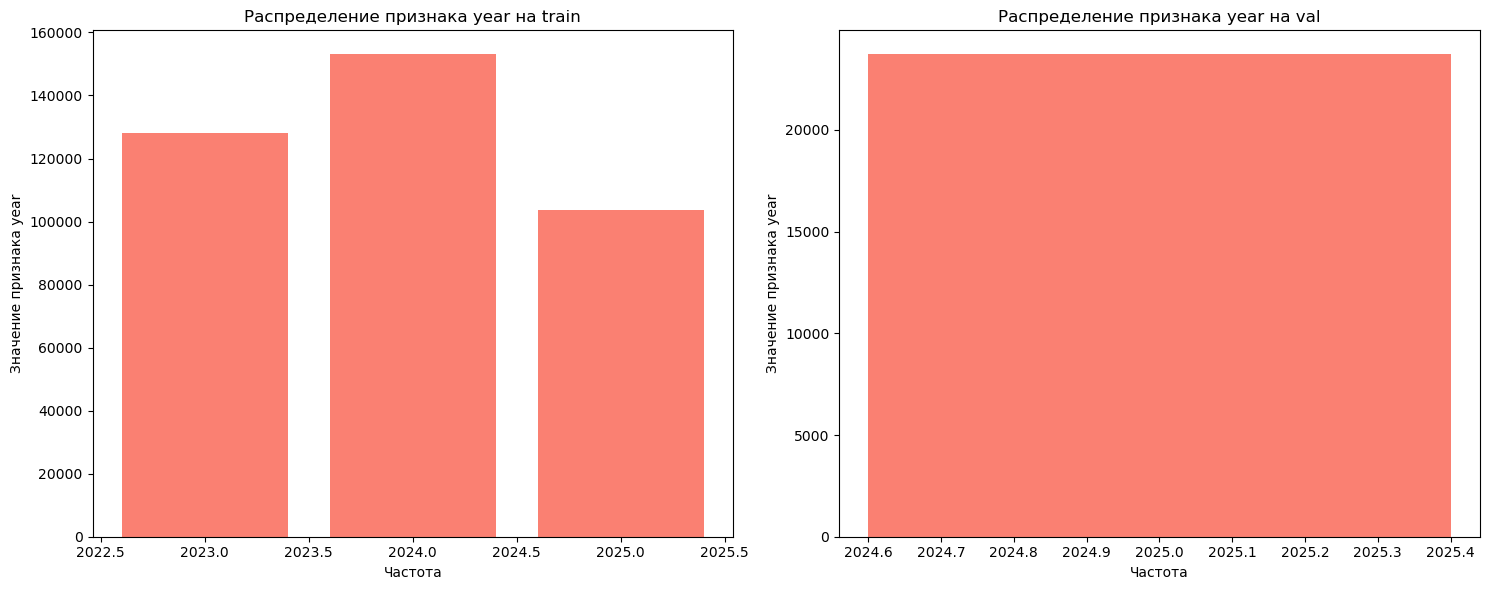

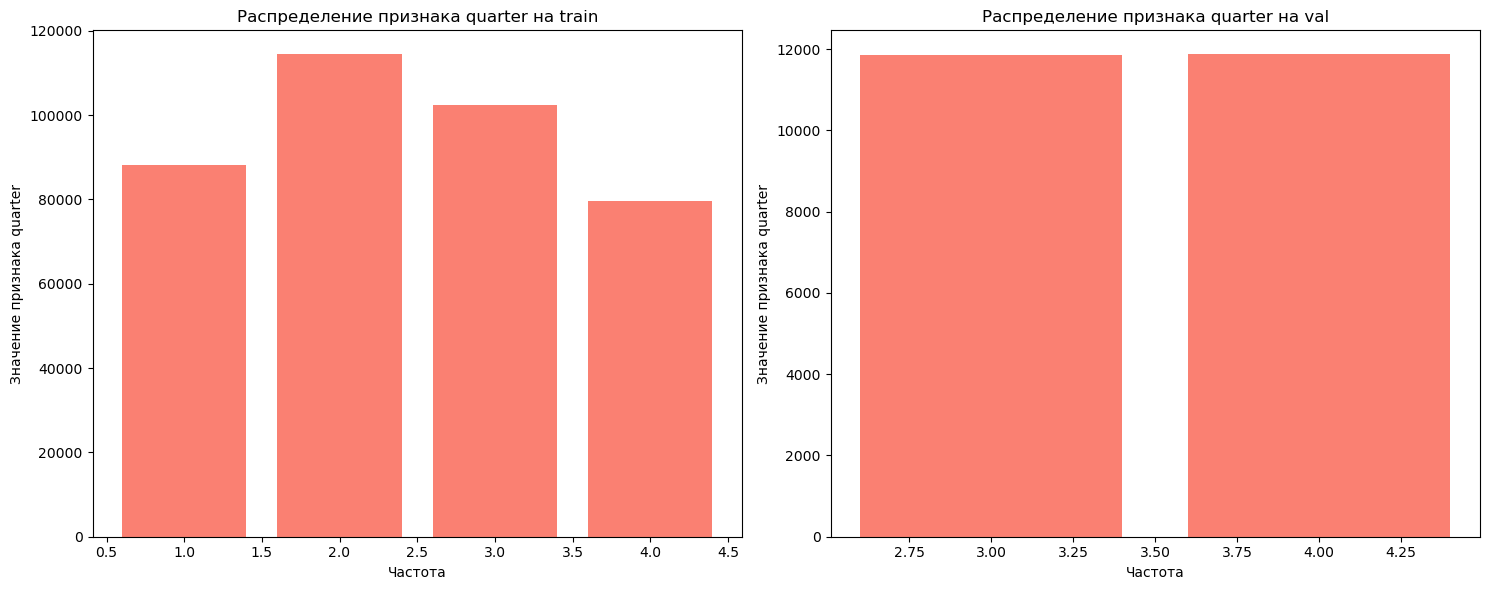

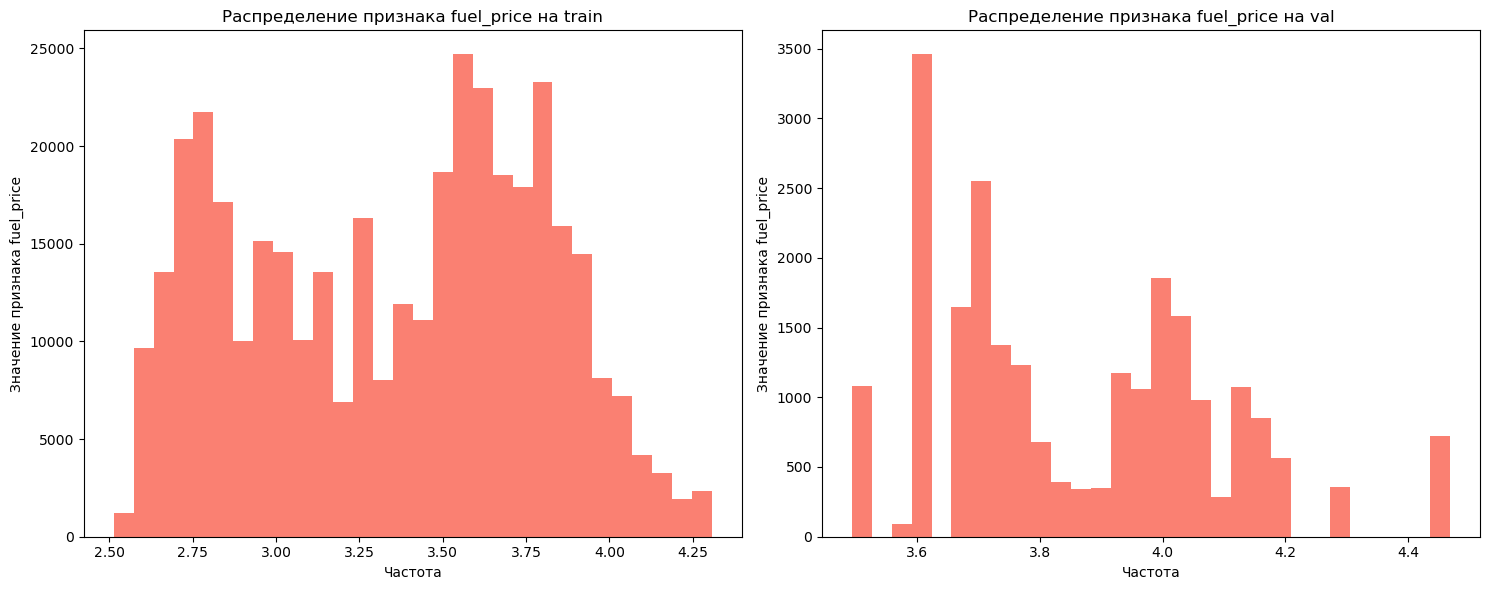

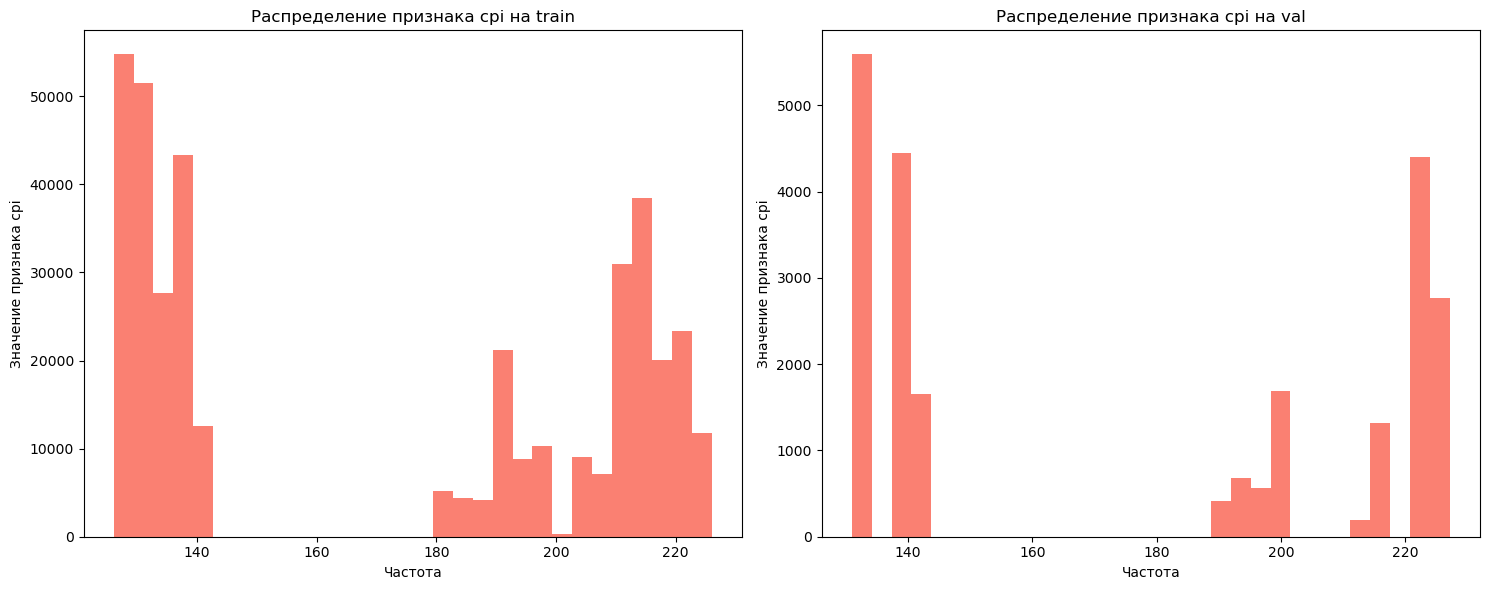

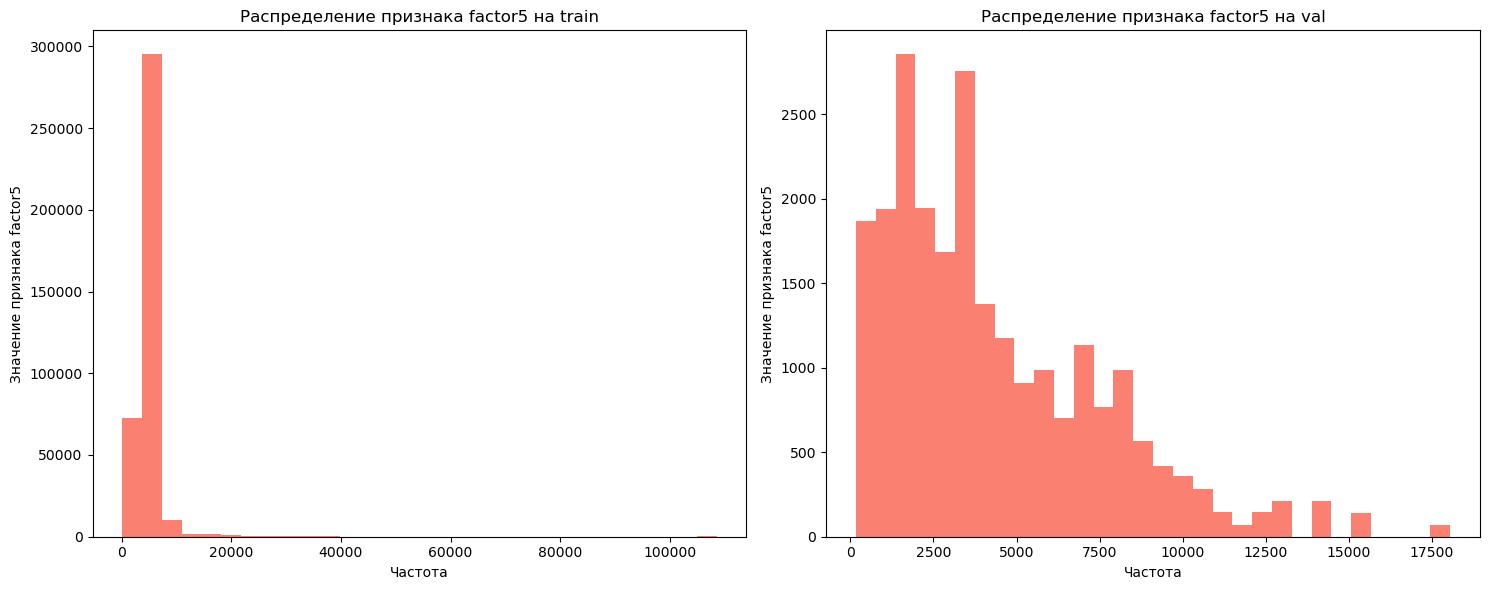

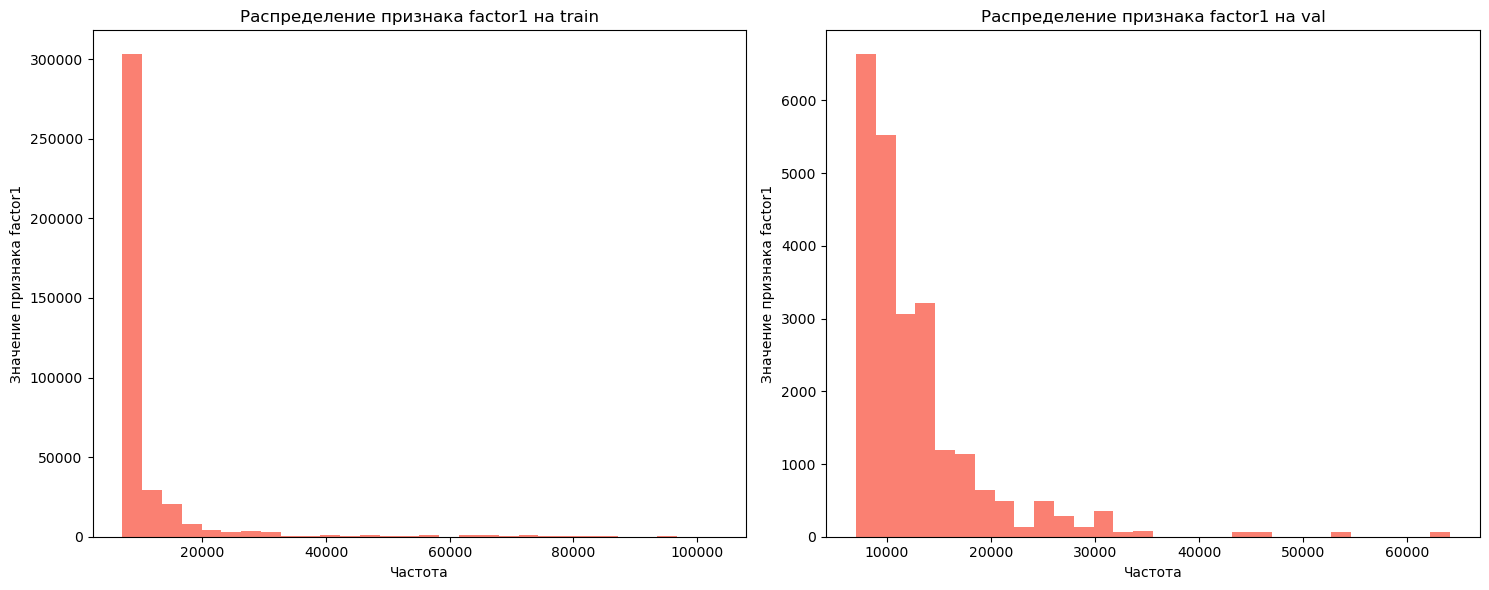

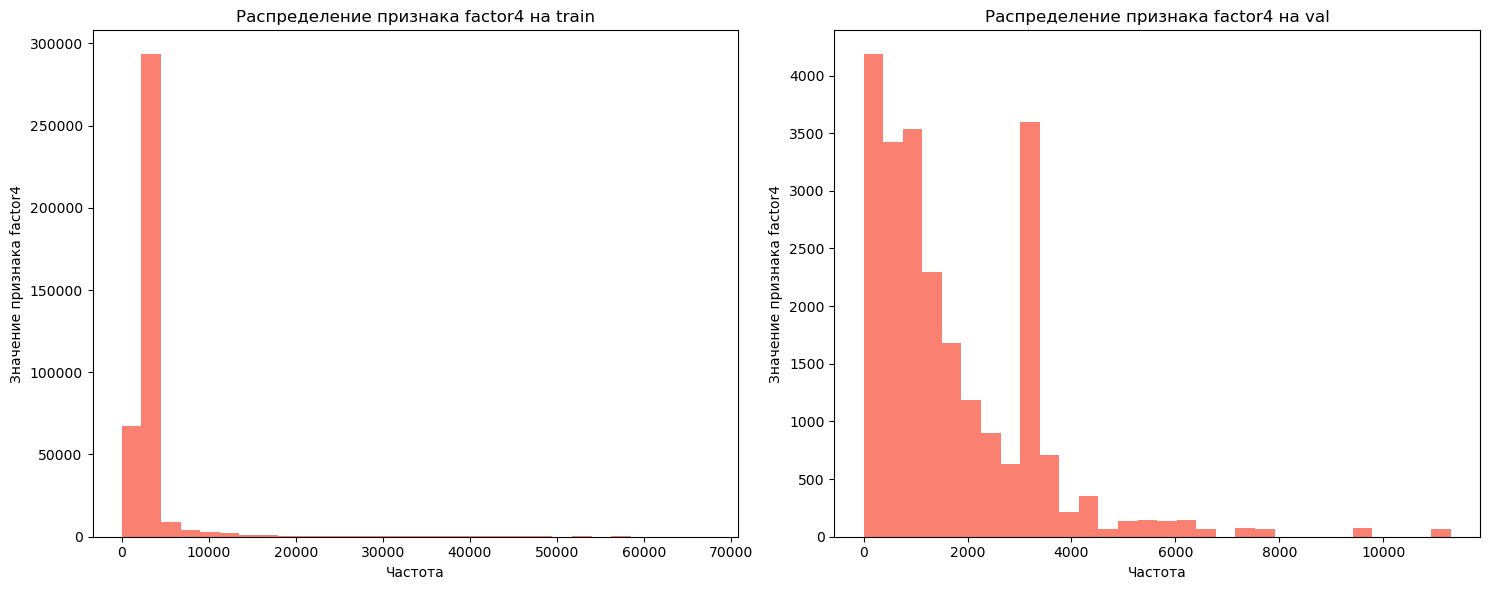

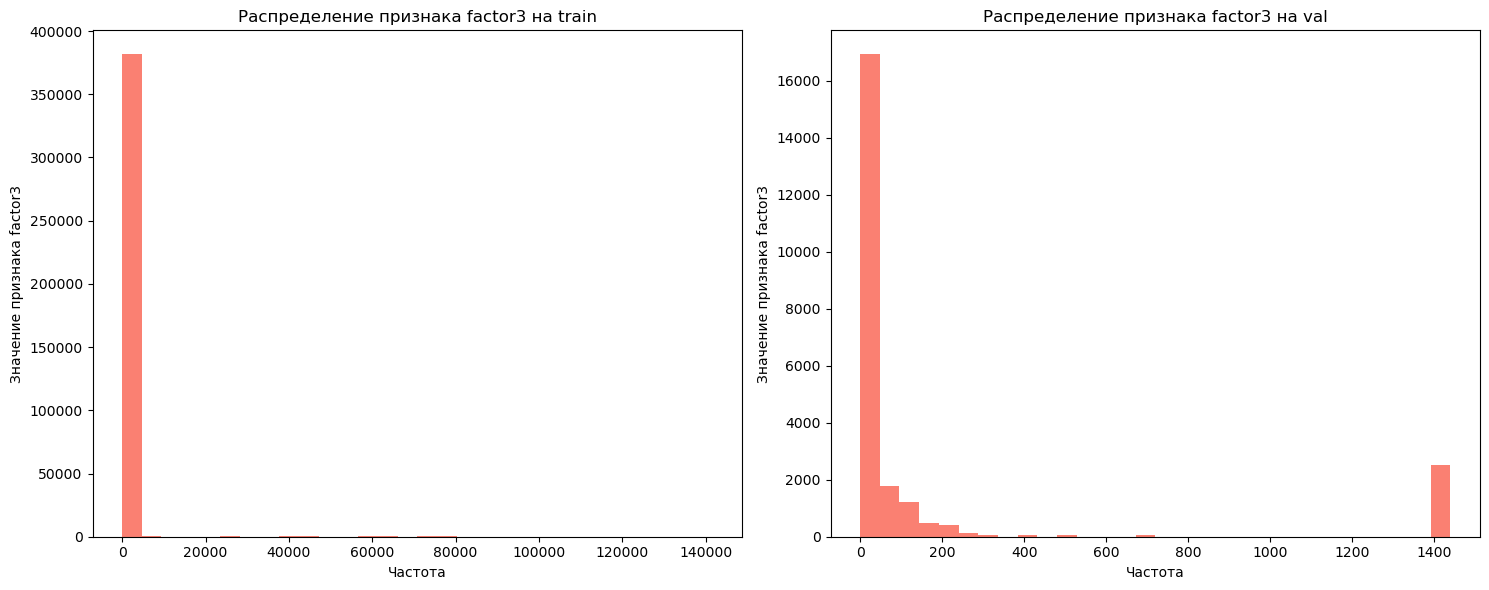

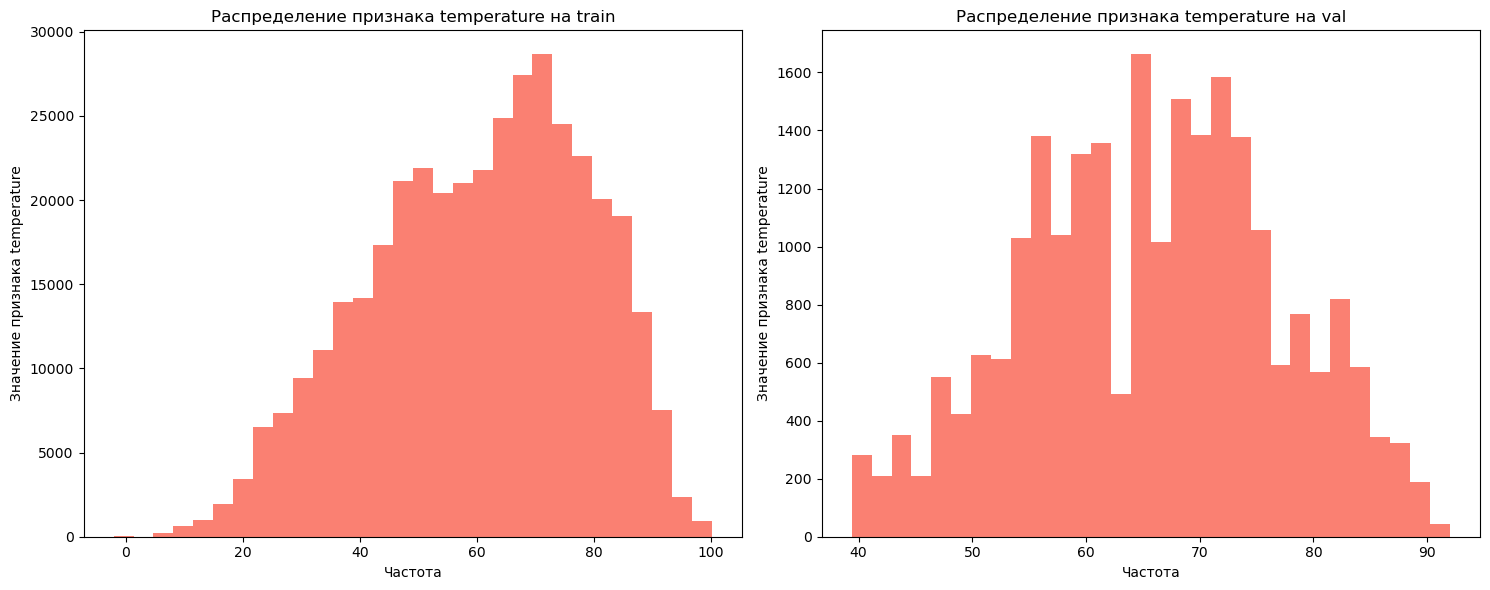

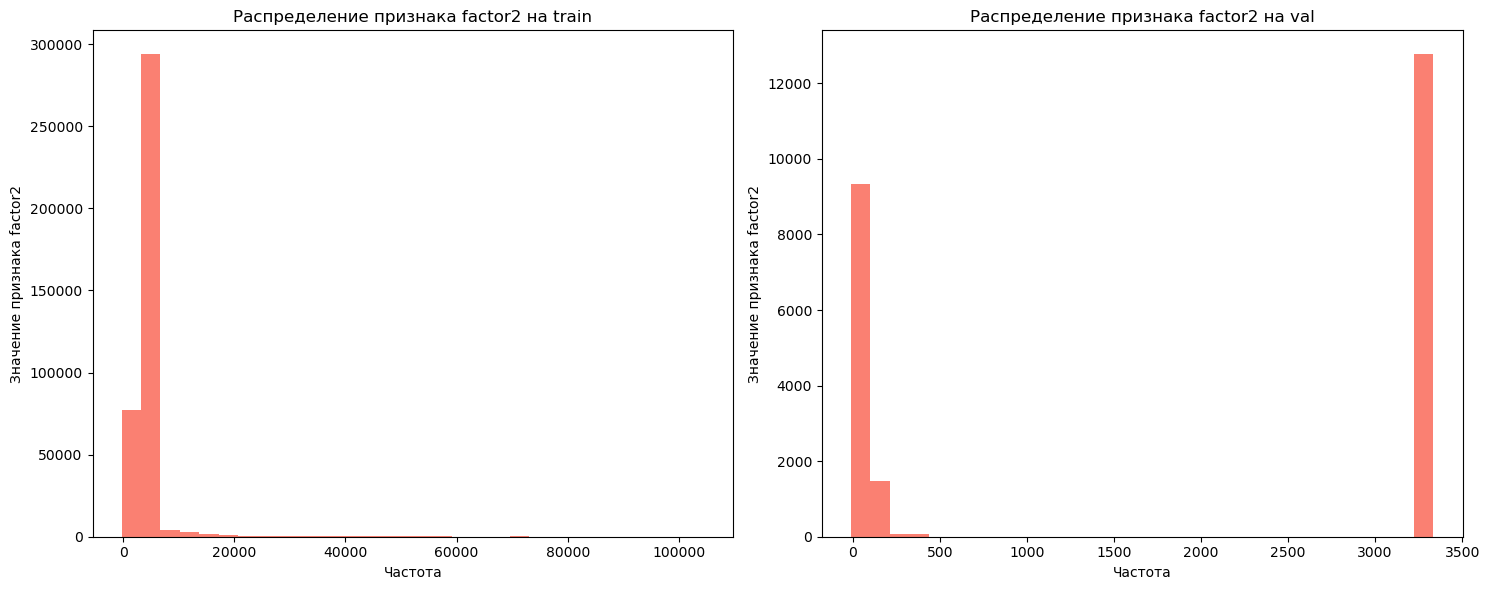

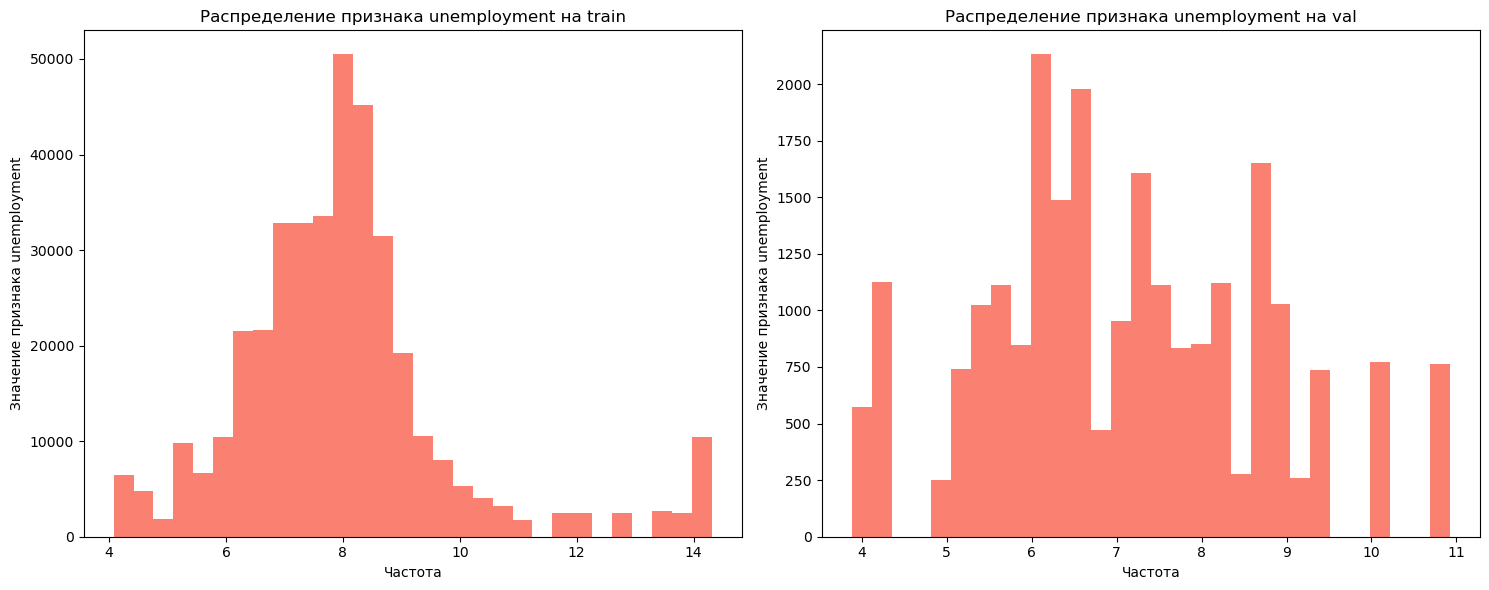

In [44]:
# Изучаем разницу распределений на val и train
categorical_cols = [
        'store',
        'dept',
        'is_holiday',
        'type',
        'month',
        'quarter',
        'year'
    ]

def show_histplot(columns, X_train, X_val):
    for col in columns:
        if col not in categorical_cols:
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
            ax1.hist(X_train[col], color='salmon', bins=30)
            ax1.set_title(f'Распределение признака {col} на train')
            ax1.set_ylabel(f'Значение признака {col}')
            ax1.set_xlabel(f'Частота')
    
            ax2.hist(X_val[col], color='salmon', bins=30)
            ax2.set_title(f'Распределение признака {col} на val')
            ax2.set_ylabel(f'Значение признака {col}')
            ax2.set_xlabel(f'Частота')
    
            plt.tight_layout()
            plt.show()

        else:
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
            train_group = X_train[col].value_counts()
            ax1.bar(train_group.index, train_group.values, color='salmon')
            ax1.set_title(f'Распределение признака {col} на train')
            ax1.set_ylabel(f'Значение признака {col}')
            ax1.set_xlabel(f'Частота')

            val_group = X_val[col].value_counts()
            ax2.bar(val_group.keys(), val_group.values, color='salmon')
            ax2.set_title(f'Распределение признака {col} на val')
            ax2.set_ylabel(f'Значение признака {col}')
            ax2.set_xlabel(f'Частота')
    
            plt.tight_layout()
            plt.show()

show_histplot(features_with_high_psi, X_train, X_val)

**Выводы**

Визуализации подтверждают результаты PSI: календарные и внешние экономические признаки заметно меняются между временными периодами. Для `year`, `month` и `quarter` это ожидаемо из-за временного разбиения и сезонности. Внешние признаки с высоким PSI проверим отдельно: обучим модель как с ними, так и без них, а решение примем по качеству на валидации.

**Задача:** удалите признаки с PSI ≥ 0.2.

Признаки с высоким PSI нестабильны и могут ухудшить качество модели в будущем. Удалите их из обучающей и валидационной выборок.

In [45]:
# Внешние нестабильные признаки исключаем, а календарные оставляем для сезонности.
date_features = ['month', 'year', 'quarter']
features_to_drop = [
    feature for feature in features_with_high_psi
    if feature not in date_features
]

X_train_psi_filtered = X_train.drop(columns=features_to_drop).copy()
X_val_psi_filtered = X_val.drop(columns=features_to_drop).copy()

print(f'X_train: {X_train.shape}')
print(f'X_train_psi_filtered: {X_train_psi_filtered.shape}')
print(f'X_val: {X_val.shape}')
print(f'X_val_psi_filtered: {X_val_psi_filtered.shape}')

X_train: (384726, 23)
X_train_psi_filtered: (384726, 14)
X_val: (23710, 23)
X_val_psi_filtered: (23710, 14)


### Шаг 4. Обучение модели CatBoost

**Задача:** обучите модель CatBoost.

Используйте **обучающую** выборку.

In [46]:
cat_features = [
    'store',
    'dept',
    'type',
]

models = {
    'base_model': CatBoostRegressor(cat_features=cat_features, random_state=RANDOM_STATE, verbose=0),
    'psi_filtered_model': CatBoostRegressor(cat_features=cat_features, random_state=RANDOM_STATE, verbose=0)
}

models['base_model'].fit(X_train, 
                         y_train,
                         eval_set=(X_val, y_val),
                         early_stopping_rounds=200,
                         use_best_model=True)
print(f'Модель base_model обучена')

models['psi_filtered_model'].fit(X_train_psi_filtered, 
                             y_train,
                             eval_set=(X_val_psi_filtered, y_val),
                             early_stopping_rounds=200,
                             use_best_model=True)
print(f'Модель psi_filtered_model обучена')

Модель base_model обучена


Модель psi_filtered_model обучена


**Задача:** оцените качество модели на валидационной выборке.

Используйте метрики:
- **MAE**.
- **RMSE**.
- **R²**.

In [47]:
# Принимает словарь models, где ключи - название модели, а значения объекты обученных моделей, X_val, y_val возвращает df с метриками моделей на val
def evaluate_model(model, model_name, X_val, y_val): 
    y_pred = model.predict(X_val)
    
    mae = round(mean_absolute_error(y_val, y_pred), 2)
    rmse = round(root_mean_squared_error(y_val, y_pred), 2)
    r2 = round(r2_score(y_val, y_pred), 2)
                       
    cur_df = pd.DataFrame({
        'model_name': [model_name],
        'mae': [mae],
        'rmse': [rmse],
        'r2_score': [r2]
    })

    return cur_df
    

In [48]:
out_df_train = pd.concat([
    evaluate_model(models['base_model'], 'base_model', X_train, y_train), 
    evaluate_model(models['psi_filtered_model'], 'psi_filtered_model', X_train_psi_filtered, y_train)
])
print(f'Метрики на train')
out_df_train

Метрики на train


,model_name,mae,rmse,r2_score
0,base_model,1799.30,4533.69,0.96
0,psi_filtered_model,1861.59,4906.99,0.95


In [49]:
out_df = pd.concat([
    evaluate_model(models['base_model'], 'base_model', X_val, y_val), 
    evaluate_model(models['psi_filtered_model'], 'psi_filtered_model', X_val_psi_filtered, y_val)
])
print(f'Метрики на validation:')
out_df

Метрики на validation:


,model_name,mae,rmse,r2_score
0,base_model,1465.25,3049.07,0.98
0,psi_filtered_model,1458.63,3053.28,0.98


**Выводы**

Обе модели показывают близкое качество. После PSI-фильтрации MAE на валидации немного снизился: 1458.63 против 1465.25 у базовой модели. RMSE почти не изменился, а R² у обеих моделей равен 0.98. Финальной выбираем PSI-модель: она использует на девять внешних признаков меньше, сохраняет качество и меньше зависит от признаков с сильным дрейфом.

In [50]:
final_model = models['psi_filtered_model']

**Задача:** проанализируйте важность признаков.

Она показывает, какие признаки наиболее важны для модели:
- Проверьте, нет ли в топе признаков, которые могут приводить к утечке данных.
- Посмотрите, какие признаки действительно влияют на продажи.


In [51]:
feature_importances = pd.DataFrame({
    'feature': final_model.feature_names_,
    'importance': final_model.feature_importances_
})

feature_importances = feature_importances.sort_values(by='importance', ascending=False)
feature_importances

,feature,importance
9,sales_1week_ago,30.736582
12,mean_sales_2week,16.707750
11,sales_4week_ago,15.926487
13,mean_sales_4week,10.241592
10,sales_2week_ago,6.141911
5,month,6.116380
8,avg_sales_before,5.551187
2,is_holiday,5.017792
1,dept,2.396077
6,quarter,0.564676


**Выводы**

Наиболее значимыми для модели оказываются признаки: `sales_1week_ago`, `sales_4week_ago` и `sales_2week_ago`. Это ожидаемое поведение, так как для временных рядов дествительно обычно большой вклад в предсказание вносят лаги. Также важным признаком оказывается `month`, что указывает на высокий вклад сезонности в объем продаж. Высокую важность для модели имеют признаки скользящего среднего `mean_sales_2week` и `mean_sales_4week`. Признак `is_holiday` также оказывается довольно важным, так как большая часть продаж происходит по праздникам.	

**Задача:** сохраните обученную модель в S3.

Модель нужно сохранить для дальнейшего использования в batch-инференсе. Код уже реализован, необходимо просто его запустить.

**Важно:** не указывайте секреты явно в ноутбуке, используйте переменные окружения.

In [52]:
# Сначала сохраняем финальную модель локально.
artifacts_dir = Path('artifacts')
artifacts_dir.mkdir(exist_ok=True)
model_path = artifacts_dir / 'catboost_model.pkl'

with model_path.open('wb') as model_file:
    pickle.dump(final_model, model_file)

print(f'Модель сохранена локально: {model_path}')

# При наличии S3-переменных ту же модель можно загрузить в Object Storage.
s3_settings = {
    'access_key': os.getenv('S3_ACCESS_KEY_ID'),
    'secret_key': os.getenv('S3_SECRET_KEY'),
    'bucket': os.getenv('S3_BUCKET'),
    'model_key': os.getenv('S3_MODEL_KEY', 'catboost_model.pkl'),
}

if all([s3_settings['access_key'], s3_settings['secret_key'], s3_settings['bucket']]):
    s3_client = boto3.client(
        's3',
        endpoint_url='https://storage.yandexcloud.net',
        aws_access_key_id=s3_settings['access_key'],
        aws_secret_access_key=s3_settings['secret_key'],
        region_name='ru-central1',
    )

    filebuffer = io.BytesIO()
    pickle.dump(final_model, filebuffer)
    filebuffer.seek(0)
    s3_client.upload_fileobj(
        Fileobj=filebuffer,
        Bucket=s3_settings['bucket'],
        Key=s3_settings['model_key'],
    )
    print(f"Модель загружена в {s3_settings['bucket']}/{s3_settings['model_key']}")
else:
    print('S3-переменные не заданы: загрузка в S3 пропущена')

Модель сохранена локально: artifacts\catboost_model.pkl
S3-переменные не заданы: загрузка в S3 пропущена
